# Sentiment Analysis
- A área de processamento de Linguagem Natural é uma área essencial do Aprendizado de máquina.
- Essa técnica permite que os computadores possam entender e processar linguagem humana.

1) > Nesse estudo irei mostrar como essa ténica permite que criemos aplicações avançadas, nos permitindo ir além e desenvolver soluções que apoiem decisões de negócio de forma robusta e proativa.
2) > Iremos treinar uma rede neural capaz de entender o sentimento predominante dos usuários e nos permitir monitorar cada mudança, permitindo-nos tomar decisões proativas em relação aos usuários.

In [1]:
import os
from IPython.display import Markdown

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import random
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import tensorflow as tf
from tensorflow.keras import layers
import tensorflow_datasets as tfds

# === Carregamento de variáveis globais e compilação de padrões Regex ===
from core.utils import clean_tweets, elapsed_time, STOP_WORDS

print(tf.__version__)

2.21.0


## Como essa técnica funciona?
- Tokenização por Subpalavras (SubwordTextEncoder): O texto de entrada é dividido em unidades menores que palavras inteiras, mas maiores que caracteres individuais (por exemplo, dividindo "infelizmente" em "in", "feliz" e "mente").
- Isso resolve o problema de palavras fora do vocabulário (OOV) e reduz o tamanho do dicionário necessário.
- Camada de Embedding: Cada subpalavra é convertida em um vetor denso (embedding), transformando a sequência de texto em uma matriz numérica de tamanho fixo.

## Técnica 1: CNNs + SubwordTextEncoder
- Essa técnica consiste em combinar Redes Neurais Convolucionais (CNNs) com um tokenizador de subpalavras (SubwordTextEncoder) para processar e classificar os textos.
- Embora as CNNs sejam mais conhecidas pelo processamento de imagens, elas são altamente eficazes no Processamento de Linguagem Natural (PLN) para extrair padrões locais e características invariantes de posição.

In [3]:
train_file_path = Path("data") / "train.csv"
train_data = pd.read_csv(train_file_path,
                        header=None,
                        engine="python",
                        encoding="latin-1")
train_data.head(3)

,0,1,2,3,4,5
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...


In [4]:
cols = ['sentiment', 'id', 'date', 'query', 'user', 'text']

# Nomeamos as colunas adequadamente
train_data.columns = cols
train_data.shape

(1600000, 6)

In [5]:
# Verificação de duplicatas
train_data[train_data.duplicated(["text"], keep=False)]

,sentiment,id,date,query,user,text
54,0,1467821455,Mon Apr 06 22:22:32 PDT 2009,NO_QUERY,CiaraRenee,I need a hug
128,0,1467841832,Mon Apr 06 22:27:55 PDT 2009,NO_QUERY,bgoers,I'm so cold
213,0,1467863684,Mon Apr 06 22:33:35 PDT 2009,NO_QUERY,DjGundam,Awwh babs... you look so sad underneith that s...
230,0,1467872175,Mon Apr 06 22:35:50 PDT 2009,NO_QUERY,edsed,I still can't find my keys.
238,0,1467872759,Mon Apr 06 22:35:59 PDT 2009,NO_QUERY,Augustina22CA,"im lonely keep me company! 22 female, california"
...,...,...,...,...,...,...
1599501,4,2193453784,Tue Jun 16 08:28:49 PDT 2009,NO_QUERY,_cammi_,getting used to twitter
1599531,4,2193474515,Tue Jun 16 08:30:28 PDT 2009,NO_QUERY,majaricious,@KhloeKardashian Definitely my Mom. And Angeli...
1599678,4,2193503347,Tue Jun 16 08:32:47 PDT 2009,NO_QUERY,ShaneLemmon,goodmorning
1599768,4,2193528075,Tue Jun 16 08:34:48 PDT 2009,NO_QUERY,rach3lizabeth,Good morning everyone.


In [6]:
train_data.drop_duplicates(subset=["text"], inplace=True)

## Como nossos dados estão distribuídos?
- Nossa base de dados é densa **(1,6 Milhão de registros)**
- A base de dados está bem balanceada **(com 800 mil tweets positivos e 800 mil tweets negativos)**

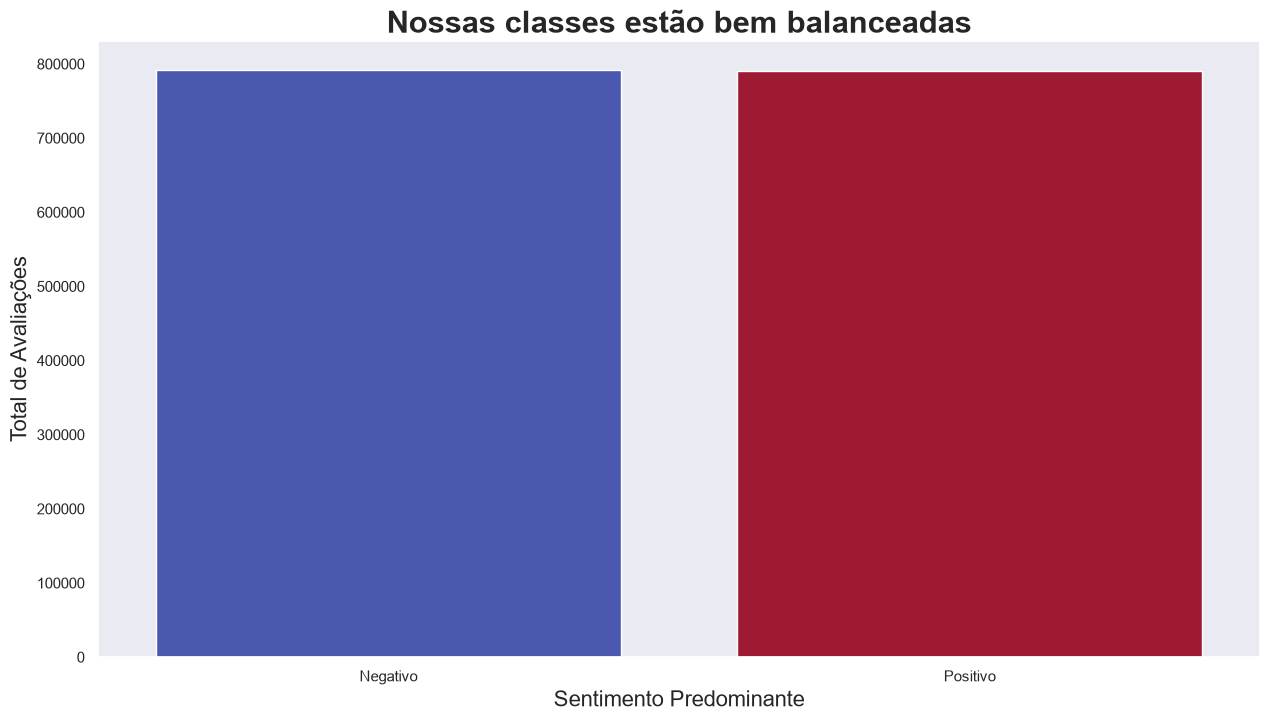

In [7]:
# --- Configuração do Tema
sns.set_theme(style="dark")

# --- Configuração da Figura ---
fig, ax = plt.subplots(figsize=(15, 8))

# --- Criação do Gráfico ---
sentiment_counts = train_data.sentiment.value_counts().reset_index()
fig = sns.barplot(sentiment_counts,
            x=["Negativo", "Positivo"], y="count", palette="coolwarm_r",
            hue="sentiment", ax=ax,
                  legend=False
           )

plt.title("Nossas classes estão bem balanceadas", fontweight="bold", size=22)
plt.xlabel("Sentimento Predominante", fontsize=16)
plt.ylabel("Total de Avaliações", fontsize=16)
plt.xticks(["Negativo", "Positivo"])

plt.show()

# Pré-processamento dos Textos
+ Os textos foram extraídos de `Tweets` e contém inconsistências que precisam ser tratadas.
+ Isso é essencial para garantir que o modelo generalize bem e tenha o máximo de desempenho nos nossos dados.

In [8]:
# Iremos usar apenas as colunas de sentimento e texto para treinar nosso modelo
data = train_data.loc[:, ["sentiment", "text"]]
data.tail()

,sentiment,text
1599995,4,Just woke up. Having no school is the best fee...
1599996,4,TheWDB.com - Very cool to hear old Walt interv...
1599997,4,Are you ready for your MoJo Makeover? Ask me f...
1599998,4,Happy 38th Birthday to my boo of alll time!!! ...
1599999,4,happy #charitytuesday @theNSPCC @SparksCharity...


# Pré-processamento dos textos

In [9]:
# Separamos as variáveis dependentes e independentes
X = data.iloc[:, 1].values
y = data.iloc[:, 0].values

### A maioria dos textos segue o padrão abaixo.
- Por isso precisamos limpar e padronizar esses textos.
- Vamos manter **apenas as palavras importantes para o modelo**

In [10]:
X[2]

'@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds'

# Porque essas Escolhas?
- Para nossos testes iniciais, vamos utilizar **apenas 20% dos dados**.  Essa pequena porção dos dados, representa um total de `320 mil tweets`.
- Escolhi essa abordagem porque realizar **testes de diferentes arquiteturas de redes neurais** em um dataset com `1.6 milhões` de tweets tornaria o projeto inviável.

In [11]:
sample_X, _, sample_y, _ = train_test_split(X, y, test_size=0.80, stratify=y, random_state=3215)
print(sample_X.shape)

(316293,)


In [12]:
unique, counts = np.unique(sample_y, return_counts=True)
print(f"NOSSAS CLASSES -> {unique[0]}, {unique[1]}  - Contagem -> {counts[0]}, {counts[1]}")

NOSSAS CLASSES -> 0, 4  - Contagem -> 158037, 158256


1. > Fizemos uma divisão estratificada dos dados (Mesma quantidade de tweets positivos e negativos no treinamento e teste).
2. > essa forma, conseguimos realizar um treinamento mais robusto da rede neural (com a mesma quantidade de amostras para as classes).

In [13]:
display(Markdown("##### Essas são nossas StopWords (palavras sem valor semântico para o modelo)"))
print(f"Total de StopWords: {len(STOP_WORDS)}", end="\n===============================\n")
print(f"StopWords: {STOP_WORDS}")

##### Essas são nossas StopWords (palavras sem valor semântico para o modelo)

Total de StopWords: 326
StopWords: {'almost', 'else', 'cannot', 'afterwards', 'since', 'a', 'is', 'being', 'himself', 'nowhere', 'i', '‘re', 'show', 'two', '’d', 'full', 'was', 'however', 'this', 'below', 'say', 'out', 'part', 'be', 'hence', 'front', 'something', 'eleven', 'what', 'into', 'should', 'at', 'take', 'all', 'become', 'once', 'by', 'thru', 'your', 'would', 'well', 'no', 'third', 'became', 'were', "'ll", 'somehow', 'those', 'get', 'from', 'their', 'beside', 'next', 'nine', 'also', 'whereby', 'only', 'towards', 'down', 'such', 'when', 'ourselves', 'anyone', 'ten', 'about', '’s', 'name', 'without', 'who', 'nor', 'not', 'whither', 'call', "'ve", 'beyond', 'for', 'again', 'seems', 'during', 'due', 'yourself', 'an', 'indeed', 'ever', 'keep', '‘s', 'me', 'even', 'becoming', 'n’t', 'some', 'which', 'they', 'its', 'wherever', 'too', 'namely', 'please', 'becomes', 'hereupon', '‘d', 'various', 'make', 'several', 'unless', 'other', 'done', 'myself', 'regarding', 'whatever', 'whereupon',

In [14]:
sample_text = train_data.loc[0, "text"]
Markdown(sample_text)

@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D

In [15]:
# Texto de exemplo para teste da função clean_tweets
text = sample_text + " 56 951"
text

"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D 56 951"

In [16]:
text = clean_tweets(sample_text)
Markdown(text)

awww that s a bummer you shoulda get david carr of third day to do it d

# Estrutura final dos tweets
### Precisamos manter uma estrutura final limpa, por isso removemos:
- Links desnecessários como `http://twitpic.com/2y1zl`
- Menções à usuários `(como @switchfoot)`
- Números aleatórios (sem valor para análise de sentimentos)
- Pontuações também não são necessárias para nossas análises.

In [17]:
@elapsed_time
def clean_tweets_with_logs(text):
    tweets = [clean_tweets(tweet) for tweet in text]
    return tweets

clean_tweets = clean_tweets_with_logs(sample_X)

06-10-2026 10:55:53 - INFO - Função clean_tweets_with_logs executada em 1608.91 segundos


In [18]:
# Iremos transformar nossa variável dependente em binária, onde 0 = Negativo e 1 = Positivo
label_data = sample_y
label_data[label_data == 4] = 1

## Salvamentos dos dados tratados (Dados parciais)
- Essa etapa é necessária para garantir que os dados estejam sempre prontos para o processamento pelos algoritmos.
- O processamentos dos textos é computacionalmente custoso **(salvar os dados nos trará uma grande economia de tempo).**
- O formato escolhido para salvamento foi o `parquet` devido à sua enorme eficiência e rapidez de processamento.
- Esses dados representam uma amostra dos dados, e serão usados para testar o desempenho de outros algoritmos.
- O que se espera é que o algoritmo que performar melhor nas amostras, tende também a performar melhor nos dados brutos.

In [19]:
path = "processed_data"
os.makedirs(path, exist_ok=True)

with open(Path(path) / "clean_tweets.parquet", "wb") as f:
    clean_tweets_df = pd.DataFrame({"text": clean_tweets, "sentiments": sample_y})
    clean_tweets_df.to_parquet(f, engine="pyarrow", index=False)
print(f"Arquivo salvo em: {Path(path) / 'clean_tweets.parquet'}")

Arquivo salvo em: processed_data\clean_tweets.parquet


In [20]:
# Amostra dos tweets padronizados (versão final)
for _ in range(5):
    random_index = random.randint(0, len(clean_tweets) - 1)
    print(f"Tweet: {clean_tweets[random_index]} -> Sentimento: {sample_y[random_index]}")

Tweet: brb nail need to dry -> Sentimento: 1
Tweet: pw be very nice kinda cloudy so not too hot decent turn out lotsa teen get my ndn burger and I be all set jingle up now -> Sentimento: 1
Tweet: yike ... please tell I you re not move from glassfish evangelist to weblogic evangelist -> Sentimento: 0
Tweet: happy belate b day scott -> Sentimento: 1
Tweet: think drink water with a straw be delicious -> Sentimento: 1


In [21]:
np.unique(label_data, return_counts=False)

array([0, 1])

In [22]:
tokenizer = tfds.deprecated.text.SubwordTextEncoder.build_from_corpus(clean_tweets, target_vocab_size=2**14)
tokenizer.vocab_size

06-10-2026 10:56:01 - INFO - SubwordTextEncoder build: trying min_token_count 112891
06-10-2026 10:56:16 - INFO - SubwordTextEncoder build: trying min_token_count 56445
06-10-2026 10:56:30 - INFO - SubwordTextEncoder build: trying min_token_count 28222
06-10-2026 10:56:42 - INFO - SubwordTextEncoder build: trying min_token_count 14111
06-10-2026 10:56:54 - INFO - SubwordTextEncoder build: trying min_token_count 7055
06-10-2026 10:57:05 - INFO - SubwordTextEncoder build: trying min_token_count 3527
06-10-2026 10:57:15 - INFO - SubwordTextEncoder build: trying min_token_count 1763
06-10-2026 10:57:25 - INFO - SubwordTextEncoder build: trying min_token_count 881
06-10-2026 10:57:35 - INFO - SubwordTextEncoder build: trying min_token_count 440
06-10-2026 10:57:44 - INFO - SubwordTextEncoder build: trying min_token_count 220
06-10-2026 10:57:53 - INFO - SubwordTextEncoder build: trying min_token_count 110
06-10-2026 10:58:03 - INFO - SubwordTextEncoder build: trying min_token_count 55
06-10

16495

In [23]:
ids = tokenizer.encode("I am very happy")
ids

[1, 476, 116, 659]

In [24]:
text = tokenizer.decode(ids)
text

'I am very happy'

In [25]:
input_data = [tokenizer.encode(sentence) for sentence in clean_tweets]

In [26]:
for _ in range(10):
    print(input_data[random.randint(0, len(input_data) - 1)])

[91, 14595, 12, 4, 630, 13, 4, 7034, 4100, 5673, 1112, 121, 21, 166, 135, 567, 38, 27, 18, 2859]
[1495, 21, 187, 1, 113, 39, 3, 25, 38, 48, 2, 193, 40, 19, 179, 10376, 1688, 4, 1318, 22, 90, 218, 23, 398, 149, 226]
[74, 39, 1626]
[2, 343, 88, 383, 75, 37, 5001]
[1, 96, 1, 126, 73, 4578, 8266, 491, 2089, 1561, 25, 20, 160, 12, 4, 1983]
[249, 6, 908, 12795, 1126, 7, 178, 712, 29, 1, 194, 1, 15, 557, 458, 3, 210, 6, 918, 24, 70, 3699, 16360]
[1, 2, 26, 266, 1, 10, 178, 396, 13965, 314, 1432]
[27, 14, 105, 3, 2, 7727, 117]
[1, 15672, 51, 3012, 5591, 199, 657, 28, 275]
[20, 30, 8258, 17, 55, 55, 2, 364, 13, 4, 574, 1079, 3214, 8, 529, 3, 143, 1, 434]


In [27]:
min_len = min([len(sentence) for sentence in input_data])
print(f"Menor texto encontrado nos tweets após tratamento: {min_len}")

Menor texto encontrado nos tweets após tratamento: 0


In [28]:
max_len = max([len(sentence) for sentence in input_data])
print(f"Maior texto encontrado nos tweets após tratamento: {max_len}")

Maior texto encontrado nos tweets após tratamento: 55


In [29]:
data_inputs = [data for data in input_data if len(data) >2]
data_inputs[:5]

[[111, 71, 8, 56, 8, 128, 2, 23, 209, 1923, 67],
 [1, 7130, 236, 17, 1323, 189, 896, 1519, 260, 25, 1, 15, 3394],
 [82,
  33,
  166,
  3,
  2618,
  1359,
  1749,
  81,
  6128,
  16348,
  107,
  1395,
  973,
  52,
  3,
  23,
  32,
  1704,
  340],
 [1, 27, 20, 1, 10, 1191, 14267],
 [39,
  240,
  19,
  4,
  1263,
  21,
  7,
  261,
  19,
  4,
  510,
  33,
  31,
  352,
  21,
  26,
  54,
  867,
  16,
  4567,
  646,
  1497,
  14778,
  2,
  11206,
  1739]]

+ > Nessa parte, precisamos **completar com zeros** os tweets mais curtos.
+ > Isso é necessário, pois a rede neural precisa que `todos os tweets tenham o mesmo tamanho.`

In [30]:
data_inputs = tf.keras.preprocessing.sequence.pad_sequences(
    input_data,
    value=0,
    padding="post",
    maxlen=max_len
)

In [31]:
for _ in range(3):
    print(data_inputs[random.randint(0, len(input_data) - 1)])

[  81  823  157    2   24 9388 2691    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0]
[    1    15    24   266     8    77     2    84 15463   236   240  1198
     2     4  4522    16     6   581     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0]
[   23   389    17     9     9    11  7237 13272   386     4  3767   361
  1927  1582     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0]


In [32]:
print(len(data_inputs), len(label_data))

316293 316293


In [33]:
train_inputs, test_inputs, train_labels, test_labels = train_test_split(
                                        data_inputs,
                                        label_data,
                                        test_size=0.3,
                                        stratify=label_data)
train_inputs

array([[    8,     2,  1200, ...,     0,     0,     0],
       [    5,   173,  1130, ...,     0,     0,     0],
       [  169, 10821,    28, ...,     0,     0,     0],
       ...,
       [ 5330,    66,    48, ...,     0,     0,     0],
       [   98,   124,   948, ...,     0,     0,     0],
       [   64,  6561,   122, ...,     0,     0,     0]],
      shape=(221405, 55), dtype=int32)

# Arquitetura da Rede Neural
- **Convolução (CNN):** Filtros convolucionais de diferentes tamanhos (varrendo 2, 3 ou mais subpalavras por vez) passam pela matriz do texto. Eles funcionam como extratores de recursos, identificando as combinações de palavras e subpalavras mais relevantes para o contexto.
- **Max-Pooling:** Uma camada de pooling extrai os valores máximos gerados pelos filtros, capturando as características mais importantes de todo o texto, independentemente de onde elas apareçam na frase.
- **Classificação:** Esses recursos são combinados em uma camada densa (fully connected) final, que gera a previsão (análise de sentimento).

In [34]:
class DCNN(tf.keras.Model):

    def __init__(self, 
                vocab_size,
                embed_dim=128,
                nb_filters=50,
                ffn_units=512,
                nb_classes=2,
                dropout_rate=0.1,
                training=False,
                name="dcnn"):
        super(DCNN, self ).__init__(name=name)
        self.embedding = layers.Embedding(vocab_size, embed_dim)
        self.bigram = layers.Conv1D(filters=nb_filters, kernel_size=2, padding="same", activation="relu")
        self.trigram = layers.Conv1D(filters=nb_filters, kernel_size=3, padding="same", activation="relu")
        self.fourgram = layers.Conv1D(filters=nb_filters, kernel_size=4, padding="same", activation="relu")
    
        self.pool = layers.GlobalMaxPool1D()
    
        self.dense = layers.Dense(units=ffn_units, activation="relu")
        self.dropout = layers.Dropout(rate=dropout_rate)
        if nb_classes == 2:
            self.last_dense = layers.Dense(units=1, activation="sigmoid")
        else:
            self.last_dense = layers.Dense(units=nb_classes, activation="softmax")

    def call(self, inputs, training=False):
        X = self.embedding(inputs)
        X_1 = self.bigram(X)
        X_1 = self.pool(X_1)
        X_2 = self.trigram(X)
        X_2 = self.pool(X_2)
        X_3 = self.fourgram(X)
        X_3 = self.pool(X_3)

        merged = tf.concat([X_1, X_2, X_3], axis=-1)        
        merged = self.dense(merged)
        merged = self.dropout(merged, training=training)
        output = self.last_dense(merged)

        return output

In [35]:
vocab_size = tokenizer.vocab_size
embed_dim = 100
nb_filters = 50
ffn_units = 128
nb_classes = len(set(train_labels))
batch_size = 64

dropout_rate = 0.5
nb_epochs = 5

In [36]:
# Instanciação da Classe
Dcnn = DCNN(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    nb_filters=nb_filters,
    ffn_units=ffn_units,
    nb_classes=nb_classes,
    dropout_rate=dropout_rate
)

In [37]:
if nb_classes == 2:
    Dcnn.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
else:
    Dcnn.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    

06-10-2026 10:58:53 - WARNING - TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.


##  Principais Vantagens (CNNs + SubwordTextEncoder):
- Lida muito bem com neologismos, erros de digitação e palavras raras, graças ao codificador de subpalavras.
- Muito mais rápida para treinar se comparada a redes recorrentes (como LSTMs), pois permite o processamento paralelo das convoluções.

In [38]:
# Cria a pasta de salvamento dos checkpoints, se necessário
folder_path = "checkpoints"
if not os.path.exists(folder_path):
    os.makedirs(folder_path, exist_ok=True)

checkpoint = folder_path
ckpt = tf.train.Checkpoint(Dcnn=Dcnn)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint, max_to_keep=5)
if ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    print("Latest Checkpoint restored")
    

Latest Checkpoint restored


In [39]:
history = Dcnn.fit(train_inputs, train_labels, 
                  batch_size=batch_size,
                  epochs=nb_epochs, verbose=1,
                  validation_split=0.1)

#ckpt_manager.save()

Epoch 1/5
3114/3114 ━━━━━━━━━━━━━━━━━━━━ 130s 41ms/step - accuracy: 0.7790 - loss: 0.4663 - val_accuracy: 0.8034 - val_loss: 0.4234
Epoch 2/5
3114/3114 ━━━━━━━━━━━━━━━━━━━━ 140s 40ms/step - accuracy: 0.8365 - loss: 0.3687 - val_accuracy: 0.8006 - val_loss: 0.4344
Epoch 3/5
3114/3114 ━━━━━━━━━━━━━━━━━━━━ 159s 45ms/step - accuracy: 0.8870 - loss: 0.2701 - val_accuracy: 0.7917 - val_loss: 0.4947
Epoch 4/5
3114/3114 ━━━━━━━━━━━━━━━━━━━━ 138s 44ms/step - accuracy: 0.9284 - loss: 0.1750 - val_accuracy: 0.7813 - val_loss: 0.6426
Epoch 5/5
3114/3114 ━━━━━━━━━━━━━━━━━━━━ 206s 66ms/step - accuracy: 0.9512 - loss: 0.1208 - val_accuracy: 0.7788 - val_loss: 0.8533


# Avaliação dos Resultados

In [40]:
results = Dcnn.evaluate(test_inputs, test_labels, batch_size=batch_size)
print(results)

1483/1483 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7815 - loss: 0.8559
[0.8559345006942749, 0.7815108299255371]


In [41]:
y_pred_test = Dcnn.predict(test_inputs)

2966/2966 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step


In [42]:
y_pred_test[:10]

array([[0.9999998 ],
       [0.903248  ],
       [0.20596883],
       [0.880822  ],
       [0.00189471],
       [0.9074435 ],
       [0.959848  ],
       [0.9820585 ],
       [0.00307357],
       [0.76337135]], dtype=float32)

In [43]:
y_pred_test = (y_pred_test > 0.5).astype(int)
y_pred_test[:10]

array([[1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1]])

# Visualização e persistência das Métricas

In [44]:
matrix = confusion_matrix(test_labels, y_pred_test)
matrix

array([[37834,  9577],
       [11155, 36322]])

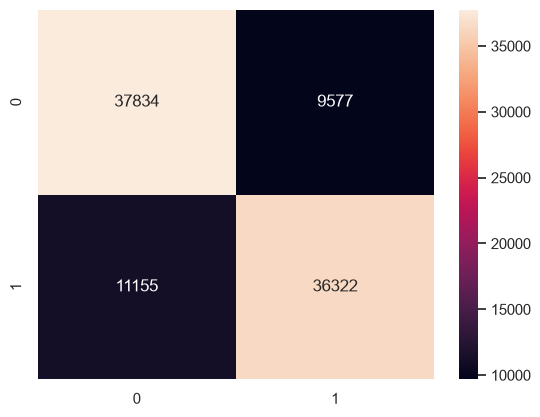

In [45]:
sns.heatmap(matrix, annot=True, robust=True, fmt=".0f")
plt.show()

In [46]:
accuracy = accuracy_score(test_labels, y_pred_test)
print(f"Acurácia: {accuracy*100:.2f}%")

Acurácia: 78.15%


In [47]:
report = classification_report(test_labels, y_pred_test)
print(report)

              precision    recall  f1-score   support

           0       0.77      0.80      0.78     47411
           1       0.79      0.77      0.78     47477

    accuracy                           0.78     94888
   macro avg       0.78      0.78      0.78     94888
weighted avg       0.78      0.78      0.78     94888



In [48]:
metrics_dir = Path("metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

with open(metrics_dir / "cnn_report.txt","w") as f:
    f.write(report)

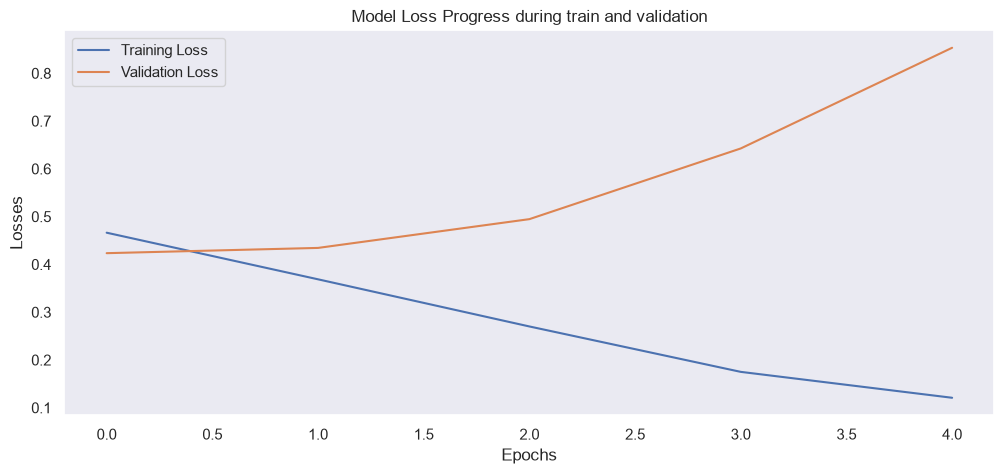

In [49]:
plt.figure(figsize=(12, 5))
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Model Loss Progress during train and validation")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend(["Training Loss", "Validation Loss"])
plt.show()

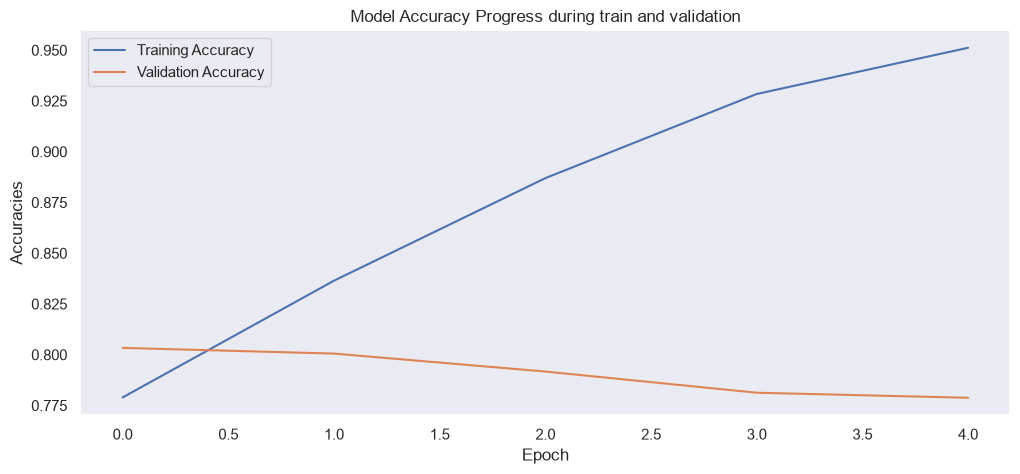

In [50]:
plt.figure(figsize=(12, 5))
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy Progress during train and validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracies")
plt.legend(["Training Accuracy", "Validation Accuracy"])
plt.show()

In [51]:
text = "you are so funny"
text = tokenizer.encode(text)
text

[8, 4092, 24, 950]

In [52]:
Dcnn(np.array([text]), training=False)

<tf.Tensor: shape=(1, 1), dtype=float32, numpy=array([[0.99942774]], dtype=float32)>